In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from charge_correlator.plot.utils import (get_data, calc_hist, get_rc_and_err, get_rc_and_err_unweighted, get_rc_and_err_new)

In [18]:
# HERWIG_PREFIX= '/nfs/roberts/pi/pi_lbh35/youqi/herwig' # old, cut on 0.2 < pT < 30 GeV for truth particle pT
HERWIG_PREFIX= '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig'
PTHAT_BINS = ['11pthat15', '15pthat20', '20pthat25', '25pthat30', '30pthat35',
              '35pthat40', '40pthat45', '45pthat50', '50pthat1000']
TRUTH_COLS = ['evid', 'xsec', 'pt', 'n', 'parton', 'nch',
              'pt1', 'q1', 'eta1', 'phi1', 'pid1', 'parent1',
              'pt2', 'q2', 'eta2', 'phi2', 'pid2', 'parent2',
              'dr', 'm', 'nparents1', 'nparents2']

EMB_FILE   = '/nfs/roberts/home/ys668/output/run12/all050124_rc_notrueptcons.root'
COLUMNS   = ['pt', 'nch', 'b', 'w', 'y1', 'y2', 'phi1', 'phi2',
             'pts', 'nchs', 'bs', 'ws', 'y1s', 'y2s', 'phi1s', 'phi2s', 'nefs']

PT_EDGES   = [15, 20, 25, 30, 40, 60]
PT_CENTERS = [17.5, 22.5, 27.5, 35, 50]
PT_XERR    = [2.5, 2.5, 2.5, 5, 10]

plt.rcParams['font.size'] = 15

In [20]:
def bin_df_in_pt(df):
    return [df[(df.pt > PT_EDGES[i]) & (df.pt < PT_EDGES[i+1])] for i in range(5)]

def get_rc_and_err_arr(df_arr, ob):
    rc_arr = []
    err_arr = []
    for df in df_arr:
        rc, err = get_rc_and_err(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

def get_mc(observables, filename_prefix, pthat_bins):
    dfs = []
    for pthat_bin in pthat_bins:
        df = pd.read_csv(f'{filename_prefix}_{pthat_bin}_rc_truth.txt', names=observables, low_memory=False)
        if pthat_bin == '11pthat15':
            df['w'] = float(df.iloc[-1]['xsec']) / 1000000
        else:
            df['w'] = float(df.iloc[-1]['xsec']) / 200000
        dfs.append(df)
    return pd.concat(dfs)

In [4]:
def get_nch_arr(df_arr):
    nch_arr = []
    for df in df_arr:
        nch = np.average(df.nch, weights=df.w)
        nch_arr.append(nch)
    return nch_arr

# Compare truth

In [22]:
# Herwig truth
df_hw = get_mc(TRUTH_COLS, HERWIG_PREFIX, PTHAT_BINS)
df_hw = df_hw.query('pt>15 and abs(parent1)>15 and abs(parent2)>15 and abs(pid1)>15 and abs(pid2)>15').copy()
df_hw.eval('b_ch = q1*q2', inplace=True)
df_hw_pt = bin_df_in_pt(df_hw)

rc_pt_hw, err_pt_hw = get_rc_and_err_arr(df_hw_pt, 'b_ch')

In [23]:
nch_pt_hw = get_nch_arr(df_hw_pt)

In [24]:
# Pythia6 truth
df_pythia6 = get_data(COLUMNS, EMB_FILE, 'MatchedTree').query('b!=0 and b!=-9 and pt>5')
df_pythia6_pt = bin_df_in_pt(df_pythia6)

rc_pythia6, err_pythia6 = get_rc_and_err_arr(df_pythia6_pt, 'b')

In [25]:
nch_pythia6 = get_nch_arr(df_pythia6_pt)

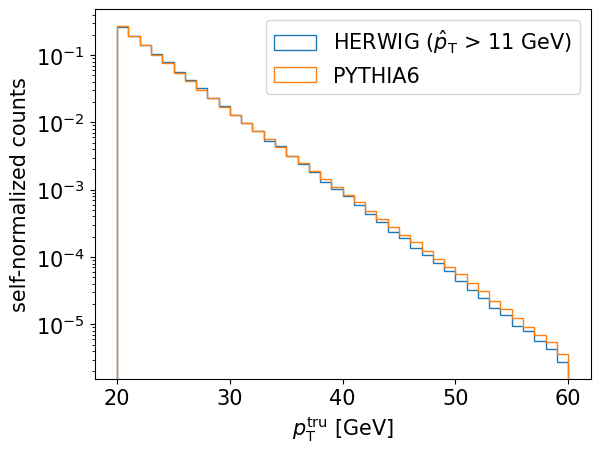

In [26]:
plt.hist(df_hw['pt'], bins=np.arange(20,61), weights=df_hw['w'], density=True, histtype='step', label=r'HERWIG ($\hat{p}_{\rm{T}}$ > 11 GeV)')
plt.hist(df_pythia6[df_pythia6.pt>20]['pt'], bins=np.arange(20,61), weights=df_pythia6[df_pythia6.pt>20]['w'], density=True, histtype='step', label='PYTHIA6')
plt.yscale('log')
plt.xlabel(r'$p_{\rm{T}}^{\rm{tru}}$ [GeV]')
plt.ylabel('self-normalized counts')
plt.legend()

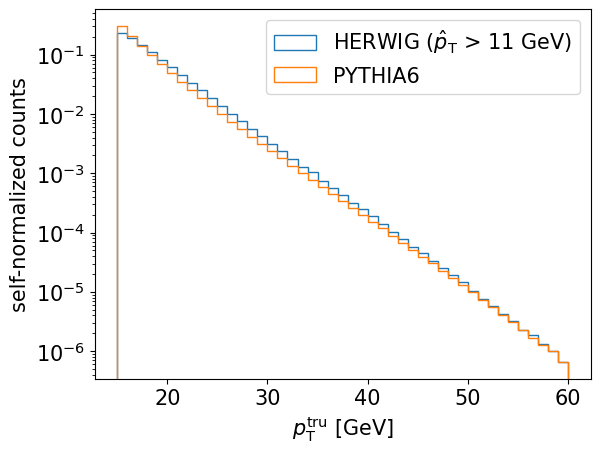

In [27]:
plt.hist(df_hw['pt'], bins=np.arange(15,61), weights=df_hw['w'], density=True, histtype='step', label=r'HERWIG ($\hat{p}_{\rm{T}}$ > 11 GeV)')
plt.hist(df_pythia6[df_pythia6.pt>15]['pt'], bins=np.arange(15,61), weights=df_pythia6[df_pythia6.pt>15]['w'], density=True, histtype='step', label='PYTHIA6')
plt.yscale('log')
plt.xlabel(r'$p_{\rm{T}}^{\rm{tru}}$ [GeV]')
plt.ylabel('self-normalized counts')
plt.legend()

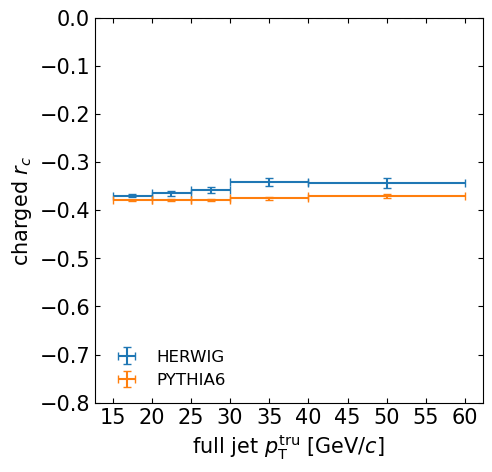

In [28]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(PT_CENTERS, rc_pt_hw, xerr=PT_XERR, yerr=err_pt_hw,
            capsize=3, ls='none', label='HERWIG')
ax.errorbar(PT_CENTERS, rc_pythia6, xerr=PT_XERR, yerr=err_pythia6,
            capsize=3, ls='none', label='PYTHIA6')
ax.axhline(0.0, color='grey', linestyle='--')
ax.set_xlabel(r'full jet $p_{\rm{T}}^{\rm{tru}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('charged $r_c$', fontsize=15)
ax.set_ylim(-0.8, 0)
ax.legend(fontsize=12, loc='lower left', frameon=False)
ax.set_xticks(np.arange(15, 65, 5))
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
plt.show()

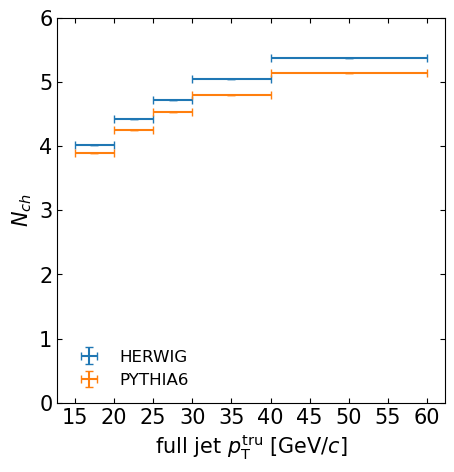

In [29]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(PT_CENTERS, nch_pt_hw, xerr=PT_XERR, yerr=0,
            capsize=3, ls='none', label='HERWIG')
ax.errorbar(PT_CENTERS, nch_pythia6, xerr=PT_XERR, yerr=0,
            capsize=3, ls='none', label='PYTHIA6')
# ax.axhline(0.0, color='grey', linestyle='--')
ax.set_xlabel(r'full jet $p_{\rm{T}}^{\rm{tru}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('$N_{ch}$', fontsize=15)
ax.set_ylim(0, 6)
ax.legend(fontsize=12, loc='lower left', frameon=False)
ax.set_xticks(np.arange(15, 65, 5))
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
plt.show()

In [30]:
np.array(nch_pt_hw) - np.array(nch_pythia6)

array([0.12336523, 0.16549931, 0.19101418, 0.24585454, 0.24397818])

In [31]:
min(df_hw['nch']), min(df_pythia6['nch']), max(df_hw['nch']), max(df_pythia6['nch'])

(2, 2, 23, 21)

# Compute reweight factors

In [32]:
RANGE_LOW, RANGE_HIGH, N_BINS = -1.2, 1.2, 2
b_bins = np.arange(RANGE_LOW, RANGE_HIGH + (RANGE_HIGH - RANGE_LOW) / N_BINS,
                   (RANGE_HIGH - RANGE_LOW) / N_BINS)
nch_bins = [1.9, 4.9, 6.9, 8.9, 11.9]

b_hw_array = []
for df in df_hw_pt:
    y, _ = np.histogramdd([df['b_ch'],df['nch']], bins=[b_bins, nch_bins], weights=df['w'], density=True)
    b_hw_array.append(y)

b_pythia6_array = []
for df in df_pythia6_pt:
    y, _ = np.histogramdd([df['b'],df['nch']], bins=[b_bins, nch_bins], weights=df['w'], density=True)
    b_pythia6_array.append(y)

In [33]:
print(b_hw_array)
print(b_pythia6_array)

[array([[0.13160817, 0.07106863, 0.01534893, 0.00104494],
       [0.05148819, 0.04208298, 0.010813  , 0.00076078]]), array([[0.11379098, 0.08304757, 0.02620613, 0.00293921],
       [0.0426722 , 0.04752205, 0.0173942 , 0.00226208]]), array([[0.10301917, 0.08560734, 0.03431106, 0.00570391],
       [0.03697268, 0.04866716, 0.0225989 , 0.00462572]]), array([[0.08960896, 0.08753515, 0.04352903, 0.00939317],
       [0.03360433, 0.04880277, 0.0273039 , 0.00705742]]), array([[0.07790109, 0.09633388, 0.04610912, 0.0141212 ],
       [0.02972305, 0.04620565, 0.03079725, 0.00973517]])]
[array([[0.13782665, 0.06673597, 0.01278375, 0.00079247],
       [0.05433563, 0.03822067, 0.00857172, 0.00061495]]), array([[0.12158045, 0.07988615, 0.02152359, 0.00233519],
       [0.04576575, 0.04432043, 0.0139389 , 0.00165034]]), array([[0.1102264 , 0.0867221 , 0.0288641 , 0.00434702],
       [0.04017773, 0.04606049, 0.01858133, 0.00287461]]), array([[0.10001855, 0.09041423, 0.03626668, 0.00663947],
       [0.035

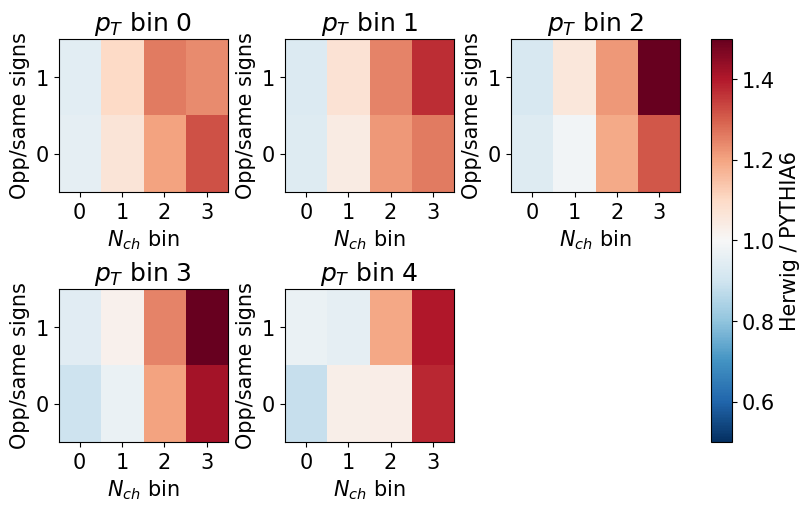

In [37]:
ratio = np.stack(b_hw_array) / np.stack(b_pythia6_array)  # (5, 2, 4)

# Use a shared color scale centered at 1 (equal fractions).
delta = np.max(np.abs(ratio - 1))

fig, axes = plt.subplots(2,3, figsize=(8, 5), layout="constrained")
for i, ax in enumerate(axes.flat[:-1]):
    im = ax.imshow(
        ratio[i],
        origin="lower",
        aspect="auto",
        cmap="RdBu_r",
        vmin=0.5, #1 - delta,
        vmax=1.5 #1 + delta,
    )
    ax.set(title=f"$p_T$ bin {i}", xlabel="$N_{ch}$ bin", ylabel="Opp/same signs")
    ax.set_xticks(range(ratio.shape[2]))
    ax.set_yticks(range(ratio.shape[1]))
    
for ax in [axes.flat[-1]]:
    ax.set_visible(False)

fig.colorbar(im, ax=axes.ravel(), label="Herwig / PYTHIA6")

Text(0.5, 1.0, 'Truth $p_T$ bin: 40-60 GeV')

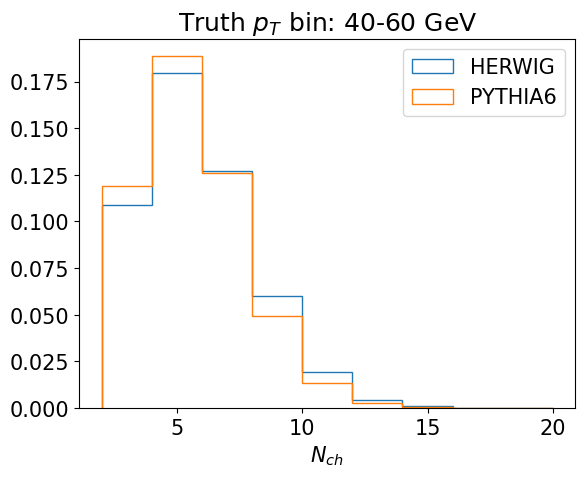

In [38]:
plt.hist(df_hw[(df_hw.pt>40) & (df_hw.pt<60)]['nch'], weights=df_hw[(df_hw.pt>40) & (df_hw.pt<60)]['w'], bins=np.arange(2, 22, 2), density=True, histtype='step', label='HERWIG')
plt.hist(df_pythia6[(df_pythia6.pt>40) & (df_pythia6.pt<60)]['nch'], weights=df_pythia6[(df_pythia6.pt>40) & (df_pythia6.pt<60)]['w'], bins=np.arange(2, 22, 2), density=True, histtype='step', label='PYTHIA6')
plt.legend()
plt.xlabel('$N_{ch}$')
plt.title('Truth $p_T$ bin: 40-60 GeV')

# Reweight

In [39]:
pt_vals = df_pythia6['pt'].to_numpy()
b_vals = df_pythia6['b'].to_numpy()
nch_vals = df_pythia6['nch'].to_numpy()

pt_idx = np.clip(np.digitize(pt_vals, PT_EDGES) - 1, 0, ratio.shape[0] - 1)
b_idx = (b_vals == 1).astype(int)  # -1 (OS) → 0, +1 (SS) → 1
nch_idx = np.clip(np.digitize(nch_vals, nch_bins) - 1, 0, ratio.shape[2] - 1)

df_pythia6 = df_pythia6.copy()
df_pythia6['r'] = ratio[pt_idx, b_idx, nch_idx]

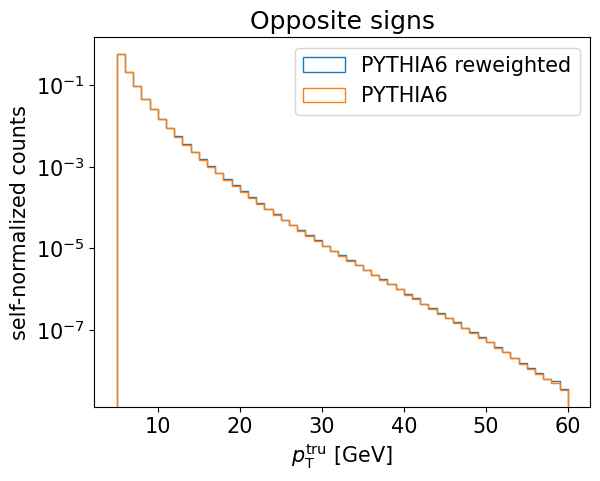

In [40]:
plt.hist(df_pythia6[df_pythia6.b==-1]['pt'], bins=np.arange(5,61), weights=df_pythia6[df_pythia6.b==-1]['w']*df_pythia6[df_pythia6.b==-1]['r'], density=True, histtype='step', label='PYTHIA6 reweighted')
plt.hist(df_pythia6[df_pythia6.b==-1]['pt'], bins=np.arange(5,61), weights=df_pythia6[df_pythia6.b==-1]['w'], density=True, histtype='step', label='PYTHIA6')
plt.yscale('log')
plt.xlabel(r'$p_{\rm{T}}^{\rm{tru}}$ [GeV]')
plt.ylabel('self-normalized counts')
plt.title('Opposite signs')
plt.legend()

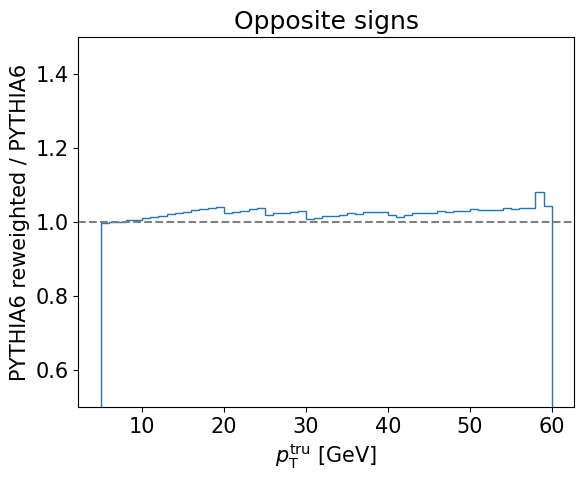

In [41]:
df = df_pythia6[df_pythia6.b == -1]
bins = np.arange(5, 61)

h_rw, _ = np.histogram(
    df['pt'], bins=bins, weights=df['w'] * df['r'], density=True
)
h_original, _ = np.histogram(
    df['pt'], bins=bins, weights=df['w'], density=True
)

# Leave bins with a zero denominator undefined.
ratio = np.divide(
    h_rw, h_original,
    out=np.full_like(h_rw, np.nan),
    where=h_original != 0,
)

plt.figure()
plt.stairs(ratio, bins)
plt.axhline(1, color='gray', linestyle='--')
plt.xlabel(r'$p_{\mathrm{T}}^{\mathrm{tru}}$ [GeV]')
plt.ylabel('PYTHIA6 reweighted / PYTHIA6')
plt.title('Opposite signs')
plt.ylim(0.5, 1.5)
plt.show()


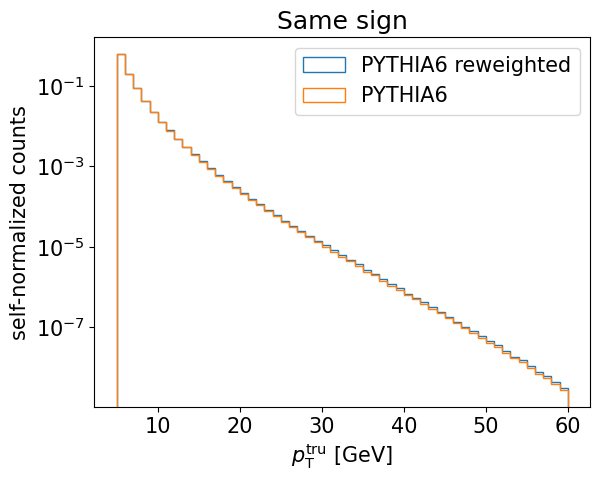

In [42]:
plt.hist(df_pythia6[df_pythia6.b==1]['pt'], bins=np.arange(5,61), weights=df_pythia6[df_pythia6.b==1]['w']*df_pythia6[df_pythia6.b==1]['r'], density=True, histtype='step', label='PYTHIA6 reweighted')
plt.hist(df_pythia6[df_pythia6.b==1]['pt'], bins=np.arange(5,61), weights=df_pythia6[df_pythia6.b==1]['w'], density=True, histtype='step', label='PYTHIA6')
plt.yscale('log')
plt.xlabel(r'$p_{\rm{T}}^{\rm{tru}}$ [GeV]')
plt.ylabel('self-normalized counts')
plt.title('Same sign')
plt.legend()

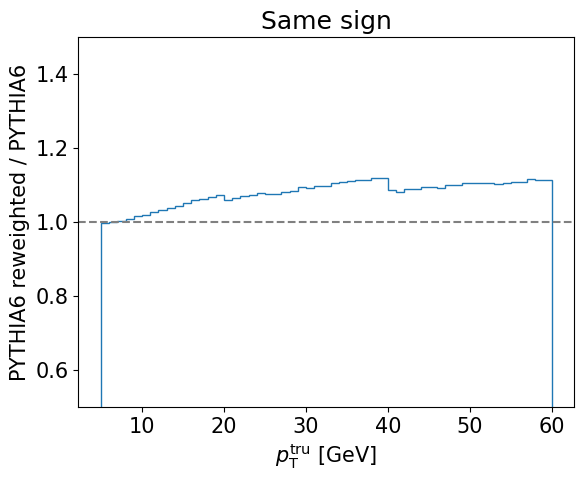

In [43]:
df = df_pythia6[df_pythia6.b == 1]
bins = np.arange(5, 61)

h_rw, _ = np.histogram(
    df['pt'], bins=bins, weights=df['w'] * df['r'], density=True
)
h_original, _ = np.histogram(
    df['pt'], bins=bins, weights=df['w'], density=True
)

# Leave bins with a zero denominator undefined.
ratio = np.divide(
    h_rw, h_original,
    out=np.full_like(h_rw, np.nan),
    where=h_original != 0,
)

plt.figure()
plt.stairs(ratio, bins)
plt.axhline(1, color='gray', linestyle='--')
plt.xlabel(r'$p_{\mathrm{T}}^{\mathrm{tru}}$ [GeV]')
plt.ylabel('PYTHIA6 reweighted / PYTHIA6')
plt.title('Same sign')
plt.ylim(0.5, 1.5)
plt.show()


# Save to csv

In [44]:
df_out = get_data(COLUMNS, EMB_FILE, 'MatchedTree') # Reload the full embedding for export.
reweight = df_pythia6['r'].reindex(df_out.index, fill_value=1.0)
# similar to:
# reweight = []
# for row_label in df_out.index:
#     if row_label in df_pythia6.index:
#         reweight.append(df_pythia6['r'].loc[row_label])
#     else:
#         reweight.append(1.0)


In [45]:
valid_w = df_out['w'].gt(0)
df_out.loc[valid_w, 'w'] *= reweight.loc[valid_w]
valid_ws = df_out['ws'].gt(0)
df_out.loc[valid_ws, 'ws'] *= reweight.loc[valid_ws]

df_out.to_csv('/nfs/roberts/home/ys668/output/run12/rc_reweighted_to_herwig_2d.csv', index=False)

In [46]:
df_out_pt = bin_df_in_pt(df_out)

rc_out, err_out = get_rc_and_err_arr(df_out_pt, 'b')

In [47]:
print(rc_pt_hw)
print(rc_out)
print(rc_pythia6)

[-0.36992758099635337, -0.36478156344493473, -0.35810526401982046, -0.34151487188915974, -0.34391867529334397]
[-0.3698751185015311, -0.36482158424621974, -0.35794273546415867, -0.341381238544582, -0.3442912278128309]
[-0.37972550416152645, -0.37892501746580687, -0.379498055300157, -0.3756346547416006, -0.37087323852796983]


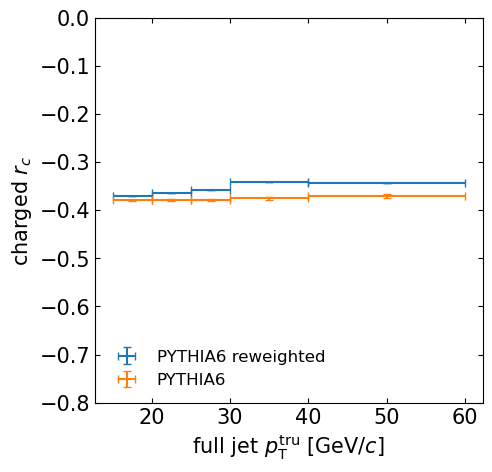

In [49]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(PT_CENTERS, rc_out, xerr=PT_XERR, yerr=err_out,
            capsize=3, ls='none', label='PYTHIA6 reweighted')
ax.errorbar(PT_CENTERS, rc_pythia6, xerr=PT_XERR, yerr=err_pythia6,
            capsize=3, ls='none', label='PYTHIA6')
ax.axhline(0.0, color='grey', linestyle='--')
ax.set_xlabel(r'full jet $p_{\rm{T}}^{\rm{tru}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('charged $r_c$', fontsize=15)
ax.set_ylim(-0.8, 0)
ax.legend(fontsize=12, loc='lower left', frameon=False)
# ax.set_xticks(np.arange(20, 65, 5))
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
plt.show()